# Análise exploratória, consultas SQL e testes de hipóteses

**Carga de energia elétrica do subsistema Sul (2021–2025)**

Este notebook corresponde à etapa de investigação dos dados do projeto. Ele usa a base integrada gerada em `integracao.ipynb` (`dados/processados/ons_projeto_integrado.parquet`) e se restringe ao recorte definido no relatório: **subsistema Sul, de 01/01/2021 a 31/12/2025, com granularidade diária**.

**Perguntas e hipóteses do relatório**

| | Pergunta | Hipótese |
|---|---|---|
| **1 — Clima** | Como as condições climáticas se relacionam com a carga de energia elétrica no subsistema Sul? | **H1:** existe associação entre as condições climáticas, especialmente a temperatura, e a carga. |
| **2 — Calendário** | Como a carga varia entre dias úteis, finais de semana e feriados nacionais? | **H2:** a carga apresenta diferenças entre dias úteis, finais de semana e feriados nacionais. |

**Ferramentas:** consultas SQL executadas com **DuckDB** diretamente sobre o arquivo Parquet; testes estatísticos com **SciPy** e **statsmodels**; gráficos com **Matplotlib**.

**Escopo:** como a base é diária, não há análise de variação por hora. A comparação entre subsistemas (Consulta 8) serve apenas de contexto, pois o estudo trata do Sul.

**Roteiro:** 1. Preparação → 2. Consultas SQL → 3. Testes de hipóteses → 4. Eventos excepcionais → 5. Dependência temporal → 6. Conclusões e implicações para a modelagem.

In [1]:
# --- BIBLIOTECAS E CONFIGURAÇÕES ---

from pathlib import Path

# Motor SQL usado nas consultas sobre o Parquet
import duckdb
# Manipulação de dados
import numpy as np
import pandas as pd
# Gráficos
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
# Testes estatísticos, regressão e séries temporais
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.tsa.stattools import acf
# Data da Páscoa, base dos feriados móveis (seção 4)
from dateutil.easter import easter

# Ampliar a exibição das tabelas no notebook
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Semente fixa para que os intervalos por bootstrap sejam reprodutíveis
rng = np.random.default_rng(42)

# Paleta categórica validada para daltonismo + tons neutros
COR = {
    "azul": "#2a78d6",
    "laranja": "#eb6834",
    "verde": "#1baf7a",
    "cinza": "#9a9993",
    "texto": "#0b0b0b",
    "texto2": "#52514e",
    "grade": "#e4e3df",
    "fundo": "#fcfcfb",
}

# Estilo padrão aplicado a todos os gráficos
plt.rcParams.update({
    "figure.facecolor": COR["fundo"],
    "axes.facecolor": COR["fundo"],
    "savefig.facecolor": COR["fundo"],
    "axes.edgecolor": COR["grade"],
    "axes.labelcolor": COR["texto2"],
    "axes.titlecolor": COR["texto"],
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": COR["grade"],
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": COR["texto2"],
    "ytick.color": COR["texto2"],
    "lines.linewidth": 2,
    "legend.frameon": False,
    "font.size": 10,
    "figure.dpi": 110,
})

# Separador de milhar no padrão brasileiro (13.000)
milhar = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

# Nomes dos dias da semana (0 = segunda-feira; 6 = domingo)
NOMES_DIAS = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]

In [2]:
# --- BASE ANALÍTICA NO DUCKDB (2021 A 2025) ---

# Caminhos da base integrada e dos arquivos brutos do ONS
CAMINHO_BASE = Path("../dados/processados/ons_projeto_integrado.parquet")
CAMINHO_ONS = Path("../dados/ONS")

# Abrir uma conexão DuckDB em memória
con = duckdb.connect()

# Visão com o recorte definido no relatório: subsistema Sul, 2021 a 2025
con.execute(f"""
    CREATE OR REPLACE VIEW carga_sul AS
    SELECT
        -- Selecionar e renomear as colunas usadas na análise
        CAST(data AS DATE)    AS data,
        year(data)            AS ano,
        month(data)           AS mes,
        dia_semana,
        val_cargaenergiamwmed AS carga,
        temperatura,
        umidade,
        precipitacao,
        tipo_dia,
        is_feriado,
        is_fds,
        is_dia_util,
        estacoes_temperatura
    -- Ler o Parquet diretamente, sem carregar em pandas
    FROM read_parquet('{CAMINHO_BASE.as_posix()}')
    -- Recorte temporal do estudo
    WHERE data BETWEEN DATE '2021-01-01' AND DATE '2025-12-31'
""")

# Macro para exibir o nome do dia da semana nas consultas
con.execute("""
    CREATE OR REPLACE MACRO nome_dia(d) AS
        CASE d
            WHEN 0 THEN 'Segunda' WHEN 1 THEN 'Terça'  WHEN 2 THEN 'Quarta'
            WHEN 3 THEN 'Quinta'  WHEN 4 THEN 'Sexta'  WHEN 5 THEN 'Sábado'
            ELSE 'Domingo'
        END
""")


# Função auxiliar usada em todas as consultas
def sql(consulta):
    """Executa uma consulta SQL no DuckDB e devolve um DataFrame."""
    return con.execute(consulta).df()


# Verificação do recorte
display(sql("""
    SELECT
        -- Total de dias e período coberto
        COUNT(*)                       AS dias,
        MIN(data)                      AS inicio,
        MAX(data)                      AS fim,
        -- COUNT(coluna) ignora nulos: a diferença dá os valores ausentes
        COUNT(*) - COUNT(carga)        AS carga_ausente,
        COUNT(*) - COUNT(temperatura)  AS temperatura_ausente,
        COUNT(*) - COUNT(umidade)      AS umidade_ausente,
        COUNT(*) - COUNT(precipitacao) AS precipitacao_ausente
    FROM carga_sul
"""))

# Quantas das 15 estações do INMET contribuíram para a temperatura regional
sql("""
    SELECT
        ano,
        -- Média, mínimo e máximo de estações ativas por dia em cada ano
        ROUND(AVG(estacoes_temperatura), 1) AS estacoes_media,
        MIN(estacoes_temperatura)           AS estacoes_minimo,
        MAX(estacoes_temperatura)           AS estacoes_maximo
    FROM carga_sul
    GROUP BY ano
    ORDER BY ano
""")

,dias,inicio,fim,carga_ausente,temperatura_ausente,umidade_ausente,precipitacao_ausente
0,1826,2021-01-01,2025-12-31,0,0,0,0


,ano,estacoes_media,estacoes_minimo,estacoes_maximo
0,2021,12.8,8.0,15.0
1,2022,13.2,9.0,14.0
2,2023,14.1,11.0,15.0
3,2024,11.8,9.0,14.0
4,2025,8.6,5.0,12.0


In [3]:
# Cópia da base em pandas para os testes estatísticos e gráficos
df = sql("SELECT * FROM carga_sul ORDER BY data")
# Garantir o tipo datetime para as operações de data em pandas
df["data"] = pd.to_datetime(df["data"])

# Conferir o tamanho e as primeiras linhas
print("Registros:", len(df))
df.head()

Registros: 1826


,data,ano,mes,dia_semana,carga,temperatura,umidade,precipitacao,tipo_dia,is_feriado,is_fds,is_dia_util,estacoes_temperatura
0,2021-01-01,2021,1,4,8564.132540,21.403220,77.117080,2.533333,Feriado nacional,True,False,False,12.0
1,2021-01-02,2021,1,5,9352.434667,21.285164,74.201791,2.766667,Final de semana,False,True,False,12.0
2,2021-01-03,2021,1,6,9449.490167,20.957071,74.301136,0.900000,Final de semana,False,True,False,12.0
3,2021-01-04,2021,1,0,12307.582125,21.571875,75.434524,2.733333,Dia útil,False,False,True,12.0
4,2021-01-05,2021,1,1,13113.233084,22.236679,85.583592,14.560000,Dia útil,False,False,True,15.0


## 2. Investigação dos dados com SQL

As oito consultas abaixo respondem a perguntas sobre comportamento temporal, comparações entre períodos e tipos de dia, relação com o clima e eventos excepcionais. Todas fazem agregações por período. As que comparam cada valor com outros (ano anterior, semanas vizinhas) usam **CTEs** (`WITH`) e **funções de janela** (`OVER`).

| Consulta | Pergunta | Recursos SQL |
|---|---|---|
| 1 | Como a carga evoluiu ano a ano? | CTE, `LAG`, `FIRST_VALUE` |
| 2 | Existe sazonalidade ao longo do ano? Ela acompanha a temperatura? | 2 CTEs, `AVG() OVER (PARTITION BY ano)` |
| 3 | Cada mês cresceu em relação ao mesmo mês do ano anterior? | CTE, `LAG() OVER (PARTITION BY mes)`, cláusula `WINDOW` |
| 4 | Como a carga varia entre os dias da semana? | CTE, `AVG() FILTER (...) OVER ()`, macro |
| 5 | Quanto a carga cai em um feriado nacional? | 2 CTEs, `LAG`/`LEAD` com deslocamento de 7 dias |
| 6 | Como a carga se comporta por faixa de temperatura? | CTE, `AVG() OVER (PARTITION BY ano)`, `CASE` |
| 7 | Quais dias fugiram muito do padrão? | 3 CTEs, `MEDIAN() OVER (... EXCLUDE CURRENT ROW)`, `ROW_NUMBER` |
| 8 | O crescimento do Sul acompanha o dos outros subsistemas? | CTE, `SUM() OVER`, `FIRST_VALUE`, leitura direta dos CSV |

In [4]:
# --- CONSULTA 1: TENDÊNCIA ANUAL ---

# Pergunta: como a carga evoluiu ano a ano?
q1 = sql("""
    -- CTE: resumo anual da carga
    WITH anual AS (
        SELECT
            ano,
            AVG(carga)       AS carga_media,
            MIN(carga)       AS carga_minima,
            MAX(carga)       AS carga_maxima
        FROM carga_sul
        GROUP BY ano
    )
    SELECT
        ano,
        -- Arredondar os indicadores para exibição
        ROUND(carga_media, 0)  AS carga_media,
        ROUND(carga_minima, 0) AS carga_minima,
        ROUND(carga_maxima, 0) AS carga_maxima,
        -- LAG: variação percentual em relação ao ano anterior
        ROUND(100 * (carga_media / LAG(carga_media) OVER (ORDER BY ano) - 1), 2)
            AS variacao_anual_pct,
        -- FIRST_VALUE: variação acumulada desde o primeiro ano (2021)
        ROUND(100 * (carga_media / FIRST_VALUE(carga_media) OVER (ORDER BY ano) - 1), 2)
            AS variacao_desde_2021_pct
    FROM anual
    ORDER BY ano
""")

# Exibir a tabela resultante
q1

,ano,carga_media,carga_minima,carga_maxima,variacao_anual_pct,variacao_desde_2021_pct
0,2021,11966.0,8277.0,14799.0,NaN,0.00
1,2022,11738.0,7742.0,16219.0,-1.90,-1.90
2,2023,12567.0,8492.0,17095.0,7.06,5.03
3,2024,13547.0,9447.0,18151.0,7.80,13.21
4,2025,13804.0,9482.0,19247.0,1.90,15.37


,mes,carga_media,indice_medio,indice_minimo,indice_maximo,temperatura_media
0,1,14538.0,107.8,102.8,116.6,23.3
1,2,15181.0,112.3,105.2,121.0,23.4
2,3,14605.0,108.1,106.5,113.0,22.5
3,4,13053.0,96.7,93.8,99.4,19.5
4,5,12747.0,94.5,91.5,96.7,16.3
5,6,12608.0,93.5,92.4,94.9,14.7
6,7,12940.0,95.9,94.2,97.2,14.3
7,8,12812.0,95.0,91.3,97.4,15.9
8,9,12780.0,94.8,90.7,97.5,18.0
9,10,12888.0,95.5,91.9,100.2,18.8


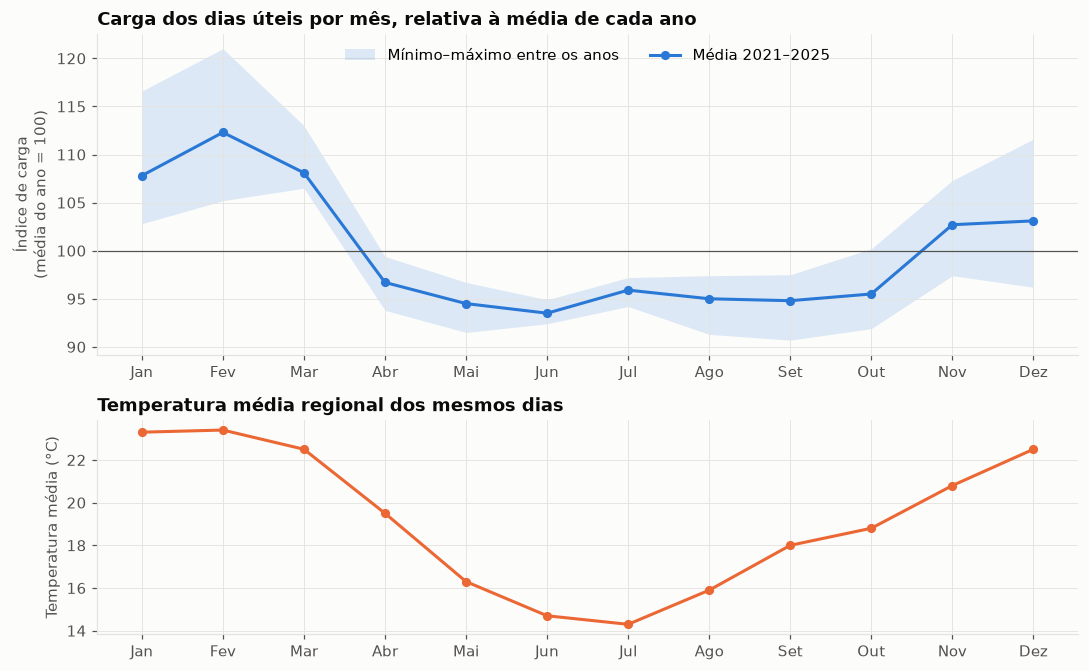

In [5]:
# --- CONSULTA 2: SAZONALIDADE MENSAL ---

# Pergunta: existe sazonalidade ao longo do ano? Ela acompanha a temperatura?
q2 = sql("""
    -- CTE 1: médias mensais de carga e temperatura em cada ano
    WITH mensal AS (
        SELECT
            ano,
            mes,
            AVG(carga)        AS carga_media,
            AVG(temperatura)  AS temperatura_media
        FROM carga_sul
        -- Somente dias úteis, para não misturar o efeito do calendário
        WHERE tipo_dia = 'Dia útil'
        GROUP BY ano, mes
    ),
    -- CTE 2: índice do mês relativo à média do próprio ano (média do ano = 100)
    indice AS (
        SELECT
            *,
            100 * carga_media / AVG(carga_media) OVER (PARTITION BY ano) AS indice_carga
        FROM mensal
    )
    SELECT
        mes,
        -- Resumo por mês do calendário, combinando os cinco anos
        ROUND(AVG(carga_media), 0)        AS carga_media,
        ROUND(AVG(indice_carga), 1)       AS indice_medio,
        ROUND(MIN(indice_carga), 1)       AS indice_minimo,
        ROUND(MAX(indice_carga), 1)       AS indice_maximo,
        ROUND(AVG(temperatura_media), 1)  AS temperatura_media
    FROM indice
    GROUP BY mes
    ORDER BY mes
""")

# Exibir a tabela da sazonalidade
display(q2)

# Rótulos dos meses para o eixo x
meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
# Figura com dois painéis: carga (em cima) e temperatura (embaixo)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True,
                               gridspec_kw={"height_ratios": [3, 2]})

# Faixa entre o menor e o maior índice observado nos anos
ax1.fill_between(q2["mes"], q2["indice_minimo"], q2["indice_maximo"],
                 color=COR["azul"], alpha=0.15, linewidth=0, label="Mínimo–máximo entre os anos")
# Índice médio de cada mês
ax1.plot(q2["mes"], q2["indice_medio"], color=COR["azul"], marker="o", markersize=5,
         label="Média 2021–2025")
# Linha de referência: média do ano
ax1.axhline(100, color=COR["texto2"], linewidth=0.8)
ax1.set_ylabel("Índice de carga\n(média do ano = 100)")
ax1.set_title("Carga dos dias úteis por mês, relativa à média de cada ano")
ax1.legend(loc="upper center", ncol=2)

# Temperatura média dos mesmos dias, para comparar com a carga
ax2.plot(q2["mes"], q2["temperatura_media"], color=COR["laranja"], marker="o", markersize=5)
ax2.set_ylabel("Temperatura média (°C)")
ax2.set_title("Temperatura média regional dos mesmos dias")
ax2.set_xticks(range(1, 13), meses)
# Com sharex=True o matplotlib esconde os rótulos do painel de cima; reexibir os meses
ax1.tick_params(axis="x", labelbottom=True)

fig.tight_layout()
plt.show()

In [6]:
# --- CONSULTA 3: COMPARAÇÃO COM O MESMO MÊS DO ANO ANTERIOR ---

# Pergunta: cada mês cresceu em relação ao mesmo mês do ano anterior?
q3 = sql("""
    -- CTE: carga e temperatura médias de cada mês de cada ano
    WITH mensal AS (
        SELECT
            ano,
            mes,
            AVG(carga)       AS carga_media,
            AVG(temperatura) AS temperatura_media
        FROM carga_sul
        GROUP BY ano, mes
    )
    SELECT
        ano,
        mes,
        ROUND(carga_media, 0) AS carga_media,
        -- LAG na janela w: compara com o mesmo mês do ano anterior
        ROUND(100 * (carga_media / LAG(carga_media) OVER w - 1), 1) AS variacao_anual_pct,
        ROUND(temperatura_media - LAG(temperatura_media) OVER w, 1)  AS diferenca_temperatura_c
    FROM mensal
    -- Janela nomeada: partição por mês e ordem por ano
    WINDOW w AS (PARTITION BY mes ORDER BY ano)
    ORDER BY ano, mes
""")

# Descartar 2021, que não tem ano anterior para comparar
comparacao = q3.dropna()

# Tabela ano x mês com escala divergente (laranja = queda, azul = crescimento)
divergente = LinearSegmentedColormap.from_list(
    "divergente", [COR["laranja"], "#f2f1ee", COR["azul"]]
)
# Reorganizar em tabela ano x mês
tabela_yoy = comparacao.pivot(index="ano", columns="mes", values="variacao_anual_pct")
tabela_yoy.columns = meses
# Exibir a tabela colorida pela variação
display(
    tabela_yoy.style
    .format("{:+.1f}%")
    .background_gradient(cmap=divergente, vmin=-20, vmax=20, axis=None)
    .set_caption("Variação da carga média mensal em relação ao mesmo mês do ano anterior")
)

# Mesma tabela ano x mês para a temperatura: diferença em °C em relação ao mesmo mês do ano anterior
# (mesmas cores: azul = mais quente, laranja = mais frio), para comparar com a tabela da carga
tabela_temp = comparacao.pivot(index="ano", columns="mes", values="diferenca_temperatura_c")
tabela_temp.columns = meses
display(
    tabela_temp.style
    .format("{:+.1f} °C")
    .background_gradient(cmap=divergente, vmin=-4, vmax=4, axis=None)
    .set_caption("Diferença de temperatura média mensal em relação ao mesmo mês do ano anterior")
)

# Correlação entre a variação da carga e a variação da temperatura
r, p = stats.spearmanr(comparacao["variacao_anual_pct"], comparacao["diferenca_temperatura_c"])
print(f"Correlação de Spearman entre variação da carga e variação da temperatura: "
      f"r = {r:.2f} (p = {p:.1e}; n = {len(comparacao)} meses)")

,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
ano,,,,,,,,,,,,
2022,+9.8%,+8.0%,-2.4%,-7.2%,-3.3%,-0.7%,-2.4%,-4.8%,-3.5%,-2.7%,-8.7%,-5.1%
2023,-4.4%,-4.3%,+7.2%,+3.7%,+9.3%,+4.5%,+4.1%,+10.1%,+10.8%,+14.4%,+16.1%,+16.6%
2024,+8.0%,+19.4%,+7.5%,+17.0%,+3.9%,+7.6%,+9.8%,+6.6%,+5.0%,+9.0%,+8.4%,-6.1%
2025,+8.9%,+6.6%,+7.7%,-2.6%,+3.0%,+0.8%,+3.4%,-4.0%,-1.9%,-4.8%,-5.9%,+11.1%


,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
ano,,,,,,,,,,,,
2022,+1.5 °C,+1.4 °C,-0.4 °C,-0.5 °C,-0.8 °C,-0.1 °C,+3.8 °C,-1.8 °C,-3.5 °C,-0.1 °C,-1.4 °C,+0.0 °C
2023,-0.6 °C,-0.7 °C,+1.7 °C,+0.4 °C,+2.7 °C,+1.8 °C,-1.4 °C,+1.9 °C,+4.1 °C,+0.8 °C,+1.5 °C,+0.7 °C
2024,-0.5 °C,+1.5 °C,-0.2 °C,+2.1 °C,-0.7 °C,+1.5 °C,-1.5 °C,-0.8 °C,+0.1 °C,+0.7 °C,+0.5 °C,-1.7 °C
2025,+1.1 °C,+0.9 °C,+0.5 °C,-1.7 °C,+1.2 °C,-3.2 °C,-0.5 °C,-0.4 °C,-1.3 °C,-0.4 °C,-0.7 °C,+2.1 °C


Correlação de Spearman entre variação da carga e variação da temperatura: r = 0.65 (p = 5.9e-07; n = 48 meses)


In [7]:
# --- CONSULTA 4: PERFIL POR DIA DA SEMANA ---

# Pergunta: como a carga varia entre os dias da semana?
q5 = sql("""
    -- CTE: carga média por dia da semana
    WITH por_dia AS (
        SELECT
            dia_semana,
            COUNT(*)   AS n_dias,
            AVG(carga) AS carga_media
        FROM carga_sul
        -- Excluir feriados para não distorcer o perfil semanal
        WHERE NOT is_feriado
        GROUP BY dia_semana
    )
    SELECT
        -- Macro nome_dia converte o número no nome do dia
        nome_dia(dia_semana) AS dia,
        n_dias,
        ROUND(carga_media, 0)   AS carga_media,
        -- FILTER + OVER (): média de segunda a sexta usada como referência
        ROUND(100 * (carga_media /
              AVG(carga_media) FILTER (WHERE dia_semana < 5) OVER () - 1), 1)
            AS diferenca_vs_seg_a_sex_pct
    FROM por_dia
    ORDER BY dia_semana
""")

# Exibir a tabela resultante
q5

,dia,n_dias,carga_media,diferenca_vs_seg_a_sex_pct
0,Segunda,256,13230.0,-1.9
1,Terça,257,13614.0,0.9
2,Quarta,252,13643.0,1.1
3,Quinta,253,13579.0,0.7
4,Sexta,258,13372.0,-0.9
5,Sábado,254,11625.0,-13.8
6,Domingo,254,10324.0,-23.5


In [8]:
# --- CONSULTA 5: FERIADOS X MESMO DIA DA SEMANA NAS SEMANAS VIZINHAS ---

# Pergunta: quanto a carga cai em um feriado nacional?
q6 = sql("""
    -- CTE 1: carga e indicador de feriado do mesmo dia da semana
    -- na semana anterior (LAG 7) e na seguinte (LEAD 7)
    WITH vizinhos AS (
        SELECT
            data,
            dia_semana,
            carga,
            is_feriado,
            LAG(carga, 7)       OVER (ORDER BY data) AS carga_semana_anterior,
            LEAD(carga, 7)      OVER (ORDER BY data) AS carga_semana_seguinte,
            LAG(is_feriado, 7)  OVER (ORDER BY data) AS feriado_anterior,
            LEAD(is_feriado, 7) OVER (ORDER BY data) AS feriado_seguinte
        FROM carga_sul
    ),
    -- CTE 2: carga de referência de cada feriado
    referencia AS (
        SELECT
            *,
            -- média apenas dos vizinhos que existem e não são feriados
            (COALESCE(CASE WHEN NOT feriado_anterior THEN carga_semana_anterior END, 0)
             + COALESCE(CASE WHEN NOT feriado_seguinte THEN carga_semana_seguinte END, 0))
            / NULLIF(
                (CASE WHEN NOT feriado_anterior THEN 1 ELSE 0 END)
                + (CASE WHEN NOT feriado_seguinte THEN 1 ELSE 0 END), 0)
            AS carga_referencia
        FROM vizinhos
        -- Somente feriados de segunda a sexta
        WHERE is_feriado AND dia_semana < 5
    )
    SELECT
        data,
        nome_dia(dia_semana) AS dia,
        ROUND(carga, 0)            AS carga_feriado,
        ROUND(carga_referencia, 0) AS carga_referencia,
        -- Variação percentual do feriado em relação à referência
        ROUND(100 * (carga / carga_referencia - 1), 1) AS variacao_pct
    FROM referencia
    -- Descartar feriados sem nenhum vizinho válido
    WHERE carga_referencia IS NOT NULL
    ORDER BY data
""")

# Exibir os feriados e resumir a variação
display(q6)
print(f"Feriados em dias de semana: {len(q6)}")
print(f"Variação mediana: {q6['variacao_pct'].median():.1f}%")
print(f"Feriados com carga abaixo da referência: {(q6['variacao_pct'] < 0).sum()} de {len(q6)}")

,data,dia,carga_feriado,carga_referencia,variacao_pct
0,2021-01-01,Sexta,8564.0,14030.0,-39.0
1,2021-04-21,Quarta,11469.0,12747.0,-10.0
2,2021-09-07,Terça,10592.0,12081.0,-12.3
3,2021-10-12,Terça,9320.0,11556.0,-19.4
4,2021-11-02,Terça,10842.0,12764.0,-15.1
5,2021-11-15,Segunda,11012.0,13069.0,-15.7
6,2022-04-21,Quinta,11325.0,12215.0,-7.3
7,2022-09-07,Quarta,10494.0,11962.0,-12.3
8,2022-10-12,Quarta,9268.0,11692.0,-20.7
9,2022-11-02,Quarta,8702.0,12124.0,-28.2


Feriados em dias de semana: 28
Variação mediana: -16.6%
Feriados com carga abaixo da referência: 28 de 28


,faixa_temperatura,n_dias,carga_media,indice_medio,umidade_media,precipitacao_media_mm
0,< 10 °C,24,13140.0,96.6,75.2,2.3
1,10–12 °C,51,12646.0,94.2,79.8,3.5
2,12–14 °C,81,12632.0,93.6,80.2,3.3
3,14–16 °C,136,12329.0,93.3,80.6,3.9
4,16–18 °C,165,12529.0,93.5,78.3,5.7
5,18–20 °C,209,12982.0,95.9,77.3,5.3
6,20–22 °C,255,13528.0,100.7,75.8,6.0
7,22–24 °C,230,14434.0,107.0,76.0,6.0
8,24–26 °C,108,15782.0,114.4,75.0,5.3
9,≥ 26 °C,17,17296.0,123.9,71.2,2.5


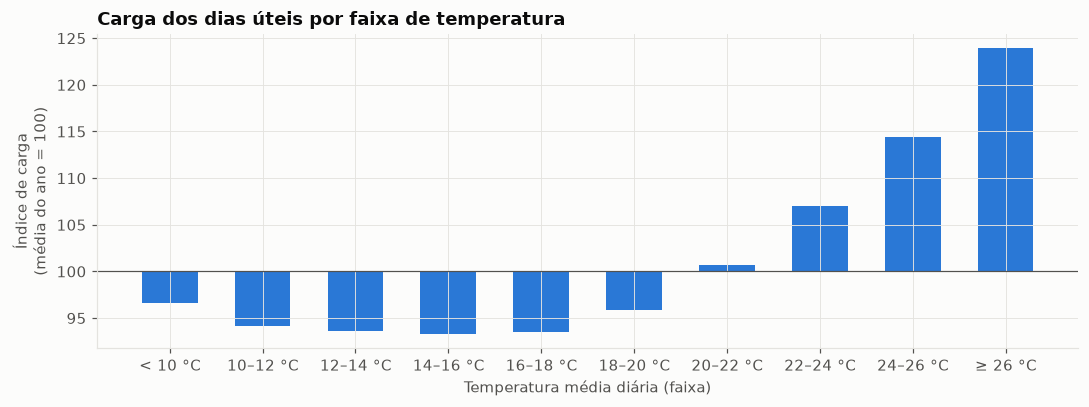

In [9]:
# --- CONSULTA 6: CARGA POR FAIXA DE TEMPERATURA ---

# Pergunta: como a carga se comporta por faixa de temperatura?
q7 = sql("""
    -- CTE: dias úteis com índice de carga e faixa de temperatura
    WITH uteis AS (
        SELECT
            *,
            -- Índice relativo à média do ano, para descontar o crescimento
            100 * carga / AVG(carga) OVER (PARTITION BY ano) AS indice_carga,
            -- Faixas de 2 °C; extremos unidos em '< 10 °C' e '≥ 26 °C'
            LEAST(GREATEST(FLOOR(temperatura / 2) * 2, 8), 26) AS faixa
        FROM carga_sul
        WHERE tipo_dia = 'Dia útil'
    )
    SELECT
        -- Rótulo legível de cada faixa
        CASE
            WHEN faixa = 8  THEN '< 10 °C'
            WHEN faixa = 26 THEN '≥ 26 °C'
            ELSE CAST(CAST(faixa AS INT) AS VARCHAR) || '–' || CAST(CAST(faixa + 2 AS INT) AS VARCHAR) || ' °C'
        END AS faixa_temperatura,
        -- Quantidade de dias e médias de carga e clima em cada faixa
        COUNT(*)                     AS n_dias,
        ROUND(AVG(carga), 0)         AS carga_media,
        ROUND(AVG(indice_carga), 1)  AS indice_medio,
        ROUND(AVG(umidade), 1)       AS umidade_media,
        ROUND(AVG(precipitacao), 1)  AS precipitacao_media_mm
    FROM uteis
    GROUP BY faixa
    ORDER BY faixa
""")

# Exibir a tabela resultante
display(q7)

# Barras com o desvio do índice em relação a 100
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(q7["faixa_temperatura"], q7["indice_medio"] - 100, bottom=100,
       color=COR["azul"], width=0.6)
ax.axhline(100, color=COR["texto2"], linewidth=0.8)
ax.set_ylabel("Índice de carga\n(média do ano = 100)")
ax.set_xlabel("Temperatura média diária (faixa)")
ax.set_title("Carga dos dias úteis por faixa de temperatura")
fig.tight_layout()
plt.show()

In [10]:
# --- CONSULTA 7: DIAS EXCEPCIONAIS ---

# Pergunta: quais dias fugiram muito do padrão?
q8 = sql("""
    -- CTE 1: referência = mediana do mesmo dia da semana
    -- nas 3 semanas anteriores e nas 3 seguintes, sem o próprio dia
    WITH referencia AS (
        SELECT
            data,
            dia_semana,
            tipo_dia,
            carga,
            temperatura,
            MEDIAN(carga) OVER (
                PARTITION BY dia_semana
                ORDER BY data
                ROWS BETWEEN 3 PRECEDING AND 3 FOLLOWING EXCLUDE CURRENT ROW
            ) AS carga_referencia
        FROM carga_sul
    ),
    -- CTE 2: desvio percentual de cada dia em relação à referência
    desvios AS (
        SELECT *, 100 * (carga / carga_referencia - 1) AS desvio_pct
        FROM referencia
    ),
    -- CTE 3: posição de cada dia no ranking de quedas e no de altas
    ranking AS (
        SELECT
            *,
            ROW_NUMBER() OVER (ORDER BY desvio_pct)      AS posicao_queda,
            ROW_NUMBER() OVER (ORDER BY desvio_pct DESC) AS posicao_alta
        FROM desvios
    )
    SELECT
        -- Classificar os dias selecionados
        CASE WHEN posicao_queda <= 10 THEN 'Muito abaixo' ELSE 'Muito acima' END AS grupo,
        data,
        nome_dia(dia_semana)        AS dia,
        tipo_dia,
        ROUND(carga, 0)             AS carga,
        ROUND(carga_referencia, 0)  AS carga_referencia,
        ROUND(desvio_pct, 1)        AS desvio_pct,
        ROUND(temperatura, 1)       AS temperatura
    FROM ranking
    -- Manter os 10 maiores desvios em cada direção
    WHERE posicao_queda <= 10 OR posicao_alta <= 10
    ORDER BY grupo, ABS(desvio_pct) DESC
""")

# Exibir a tabela resultante
q8

,grupo,data,dia,tipo_dia,carga,carga_referencia,desvio_pct,temperatura
0,Muito abaixo,2021-01-01,Sexta,Feriado nacional,8564.0,13795.0,-37.9,21.4
1,Muito abaixo,2021-04-02,Sexta,Dia útil,9452.0,13505.0,-30.0,19.3
2,Muito abaixo,2024-01-01,Segunda,Feriado nacional,10472.0,14910.0,-29.8,22.4
3,Muito abaixo,2023-04-07,Sexta,Dia útil,9501.0,13454.0,-29.4,18.4
4,Muito abaixo,2022-04-15,Sexta,Dia útil,8311.0,11699.0,-29.0,14.4
5,Muito abaixo,2023-12-25,Segunda,Feriado nacional,10870.0,15167.0,-28.3,23.9
6,Muito abaixo,2022-11-02,Quarta,Feriado nacional,8702.0,12061.0,-27.9,12.9
7,Muito abaixo,2025-01-01,Quarta,Feriado nacional,11100.0,14992.0,-26.0,24.6
8,Muito abaixo,2024-12-25,Quarta,Feriado nacional,10677.0,14254.0,-25.1,21.7
9,Muito abaixo,2023-04-21,Sexta,Feriado nacional,9641.0,12619.0,-23.6,15.5


participacao_pct                                  crescimento_desde_2021_pct                                 
subsistema         Nordeste Norte Sudeste/Centro-Oeste   Sul                   Nordeste Norte Sudeste/Centro-Oeste   Sul
ano                                                                                                                     
2021                   16.6   8.7                 57.2  17.5                        0.0   0.0                  0.0   0.0
2022                   16.2   9.0                 57.7  17.1                       -2.0   3.8                  1.3  -1.9
2023                   16.4   9.7                 56.8  17.1                        6.3  19.3                  6.9   5.0
2024                   16.6   9.9                 56.3  17.2                       15.1  30.6                 13.5  13.2
2025                   16.7  10.4                 55.6  17.3                       16.4  38.8                 12.9  15.4

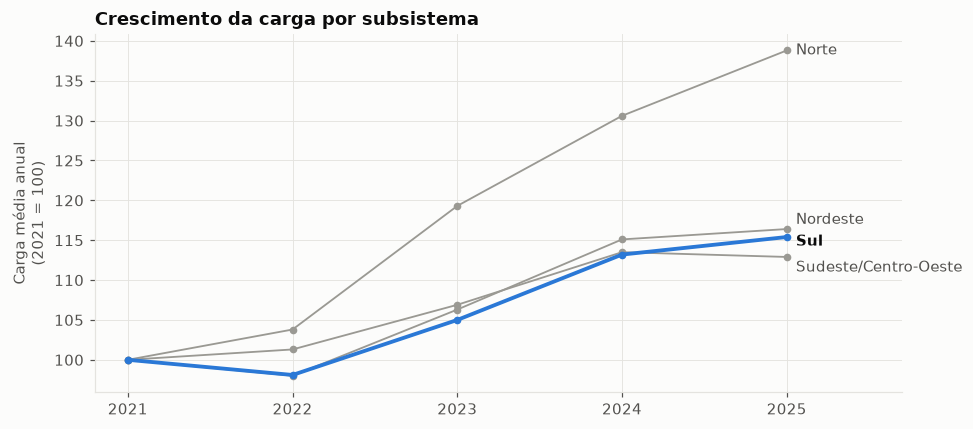

In [11]:
# --- CONSULTA 8: COMPARAÇÃO ENTRE SUBSISTEMAS ---

# Pergunta: o crescimento do Sul acompanha o dos outros subsistemas?

# Localizar os arquivos brutos do ONS de 2021 a 2025
arquivos_ons = sorted(CAMINHO_ONS.glob("CARGA_ENERGIA_202[1-5].csv"))

# Executar somente se os cinco arquivos estiverem disponíveis
if len(arquivos_ons) == 5:
    # Montar a lista de arquivos no formato aceito pelo read_csv do DuckDB
    lista_arquivos = "[" + ", ".join(f"'{a.as_posix()}'" for a in arquivos_ons) + "]"

    q9 = sql(f"""
        -- CTE: carga média anual de cada subsistema
        WITH anual AS (
            SELECT
                id_subsistema,
                nom_subsistema,
                year(din_instante)         AS ano,
                AVG(val_cargaenergiamwmed) AS carga_media
            -- Ler os CSV brutos diretamente
            FROM read_csv({lista_arquivos}, delim = ';', header = true)
            GROUP BY id_subsistema, nom_subsistema, year(din_instante)
        )
        SELECT
            nom_subsistema AS subsistema,
            ano,
            ROUND(carga_media, 0) AS carga_media,
            -- Participação de cada subsistema na carga total do ano
            ROUND(100 * carga_media / SUM(carga_media) OVER (PARTITION BY ano), 1)
                AS participacao_pct,
            -- Crescimento acumulado desde 2021 em cada subsistema
            ROUND(100 * (carga_media / FIRST_VALUE(carga_media) OVER (
                PARTITION BY id_subsistema ORDER BY ano) - 1), 1)
                AS crescimento_desde_2021_pct
        FROM anual
        ORDER BY subsistema, ano
    """)

    # Tabela com participação e crescimento por ano e subsistema
    display(q9.pivot(index="ano", columns="subsistema",
                     values=["participacao_pct", "crescimento_desde_2021_pct"]))

    # Gráfico do crescimento, com o Sul em destaque
    fig, ax = plt.subplots(figsize=(9, 4))
    # deslocamento vertical dos rótulos para evitar sobreposição (em pontos)
    ajuste_rotulo = {"Nordeste": 6, "Sul": -3, "Sudeste/Centro-Oeste": -7}
    for nome, grupo in q9.groupby("subsistema"):
        destaque = nome == "Sul"
        # Converter o crescimento em índice (2021 = 100)
        indice = 100 + grupo["crescimento_desde_2021_pct"]
        ax.plot(grupo["ano"], indice,
                color=COR["azul"] if destaque else COR["cinza"],
                linewidth=2.5 if destaque else 1.2, marker="o", markersize=4)
        # Nome do subsistema no fim de cada linha
        ax.annotate(nome, (grupo["ano"].iloc[-1], indice.iloc[-1]),
                    xytext=(6, ajuste_rotulo.get(nome, 0)), textcoords="offset points", va="center",
                    color=COR["texto"] if destaque else COR["texto2"],
                    fontweight="bold" if destaque else "normal")
    ax.set_xticks(range(2021, 2026))
    ax.set_xlim(2020.8, 2025.7)
    ax.set_ylabel("Carga média anual\n(2021 = 100)")
    ax.set_title("Crescimento da carga por subsistema")
    fig.tight_layout()
    plt.show()
else:
    # Aviso caso os arquivos não estejam na pasta
    print("Arquivos brutos do ONS (2021 a 2025) não encontrados em", CAMINHO_ONS)

In [12]:
# --- H2: DESCRIÇÃO DOS GRUPOS E INTERVALOS DE CONFIANÇA ---

# Separar a carga de cada tipo de dia
ordem_tipos = ["Dia útil", "Final de semana", "Feriado nacional"]
grupos = {tipo: df.loc[df["tipo_dia"] == tipo, "carga"] for tipo in ordem_tipos}


# Função auxiliar: média e IC 95% pela distribuição t
def ic_media(x, nivel=0.95):
    """Intervalo de confiança t de Student para a média."""
    x = np.asarray(x, dtype=float)
    media = x.mean()
    margem = stats.t.ppf((1 + nivel) / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return media, media - margem, media + margem


# Tabela com n, média, IC 95% e mediana de cada grupo
resumo_h2 = pd.DataFrame(
    [(tipo, len(x), *ic_media(x), x.median()) for tipo, x in grupos.items()],
    columns=["tipo_dia", "n", "media", "ic95_inferior", "ic95_superior", "mediana"],
).round(0)

# Normalidade dentro de cada grupo (justifica testes não paramétricos)
resumo_h2["p_shapiro"] = [stats.shapiro(x).pvalue for x in grupos.values()]

display(resumo_h2)

# Kruskal-Wallis
H, p_kw = stats.kruskal(*grupos.values())
# Tamanho de efeito ε² do Kruskal-Wallis
eps2 = (H - len(grupos) + 1) / (len(df) - len(grupos))
print(f"Kruskal-Wallis: H = {H:.1f}; p = {p_kw:.1e}; tamanho de efeito ε² = {eps2:.2f}")

# Comparações par a par (Mann-Whitney + correção de Holm)
pares = []
for a, b in [(0, 1), (0, 2), (1, 2)]:
    xa, xb = grupos[ordem_tipos[a]], grupos[ordem_tipos[b]]
    # Teste de Mann-Whitney bilateral entre os dois grupos
    u, p = stats.mannwhitneyu(xa, xb, alternative="two-sided")
    r_rb = 2 * u / (len(xa) * len(xb)) - 1  # correlação rank-bisserial
    pares.append((ordem_tipos[a], ordem_tipos[b], u, p, r_rb))

# Organizar os resultados das comparações
pares = pd.DataFrame(pares, columns=["grupo_a", "grupo_b", "U", "p_valor", "r_rank_bisserial"])
# Corrigir os p-valores para múltiplos testes (Holm)
pares["p_ajustado_holm"] = multipletests(pares["p_valor"], method="holm")[1]
pares["rejeita_H0_5pct"] = pares["p_ajustado_holm"] < 0.05

# Exibir a tabela das comparações par a par
pares.round({"U": 0, "r_rank_bisserial": 2})

,tipo_dia,n,media,ic95_inferior,ic95_superior,mediana,p_shapiro
0,Dia útil,1276,13487.0,13404.0,13570.0,13303.0,1.682845e-17
1,Final de semana,508,10975.0,10841.0,11109.0,10757.0,4.001037e-08
2,Feriado nacional,42,10745.0,10333.0,11156.0,10634.0,2.022599e-01


Kruskal-Wallis: H = 689.7; p = 1.7e-150; tamanho de efeito ε² = 0.38


,grupo_a,grupo_b,U,p_valor,r_rank_bisserial,p_ajustado_holm,rejeita_H0_5pct
0,Dia útil,Final de semana,572926.0,1.165870e-141,0.77,3.497611e-141,True
1,Dia útil,Feriado nacional,49323.0,1.673174e-20,0.84,3.346347e-20,True
2,Final de semana,Feriado nacional,11466.0,4.203991e-01,0.07,4.203991e-01,False


In [13]:
# --- H2: TESTES PAREADOS ---

# Função auxiliar: IC por reamostragem (bootstrap)
def ic_bootstrap(x, estatistica=np.mean, n_amostras=10_000, nivel=0.95):
    """Intervalo de confiança percentil por bootstrap."""
    x = np.asarray(x, dtype=float)
    amostras = rng.choice(x, size=(n_amostras, len(x)), replace=True)
    valores = estatistica(amostras, axis=1)
    return np.quantile(valores, [(1 - nivel) / 2, (1 + nivel) / 2])


# Semanas de segunda a domingo
semanas = df.assign(semana=df["data"].dt.to_period("W-SUN"))
# Média dos dias úteis de cada semana e quantos dias úteis ela teve
uteis_semana = semanas[semanas["tipo_dia"] == "Dia útil"].groupby("semana")["carga"].agg(["mean", "count"])
# Carga do sábado e do domingo de cada semana (sem feriados)
sabado = semanas[(semanas["dia_semana"] == 5) & ~semanas["is_feriado"]].groupby("semana")["carga"].mean()
domingo = semanas[(semanas["dia_semana"] == 6) & ~semanas["is_feriado"]].groupby("semana")["carga"].mean()

# Juntar por semana e manter só as semanas com todos os valores
pareado = pd.concat(
    {"uteis": uteis_semana["mean"], "n_uteis": uteis_semana["count"], "sabado": sabado, "domingo": domingo},
    axis=1,
).dropna()
pareado = pareado[pareado["n_uteis"] >= 3]  # semanas com pelo menos 3 dias úteis

# Pares a testar: dia avaliado x referência
comparacoes = {
    "Sábado × dias úteis da mesma semana": (pareado["sabado"], pareado["uteis"]),
    "Domingo × dias úteis da mesma semana": (pareado["domingo"], pareado["uteis"]),
    "Feriado (seg–sex) × mesmo dia nas semanas vizinhas": (q6["carga_feriado"], q6["carga_referencia"]),
}

# Para cada comparação: variação %, IC por bootstrap e teste de Wilcoxon
linhas = []
for nome, (x, referencia) in comparacoes.items():
    variacao = 100 * (np.asarray(x) / np.asarray(referencia) - 1)
    ic_inf, ic_sup = ic_bootstrap(variacao)
    w = stats.wilcoxon(x, referencia)
    linhas.append((nome, len(variacao), variacao.mean(), ic_inf, ic_sup,
                   np.median(variacao), (variacao < 0).mean() * 100, w.pvalue))

# Organizar e exibir os resultados
testes_pareados = pd.DataFrame(linhas, columns=[
    "comparacao", "n_pares", "variacao_media_pct", "ic95_inferior", "ic95_superior",
    "variacao_mediana_pct", "pares_com_queda_pct", "p_wilcoxon",
])
testes_pareados.round({c: 1 for c in testes_pareados.columns if c != "p_wilcoxon"})

,comparacao,n_pares,variacao_media_pct,ic95_inferior,ic95_superior,variacao_mediana_pct,pares_com_queda_pct,p_wilcoxon
0,Sábado × dias úteis da mesma semana,246,-13.7,-14.2,-13.1,-13.8,99.2,4.337032e-42
1,Domingo × dias úteis da mesma semana,246,-23.6,-24.3,-23.0,-24.2,100.0,4.180735e-42
2,Feriado (seg–sex) × mesmo dia nas semanas vizi...,28,-18.9,-22.1,-16.1,-16.6,100.0,7.450581e-09


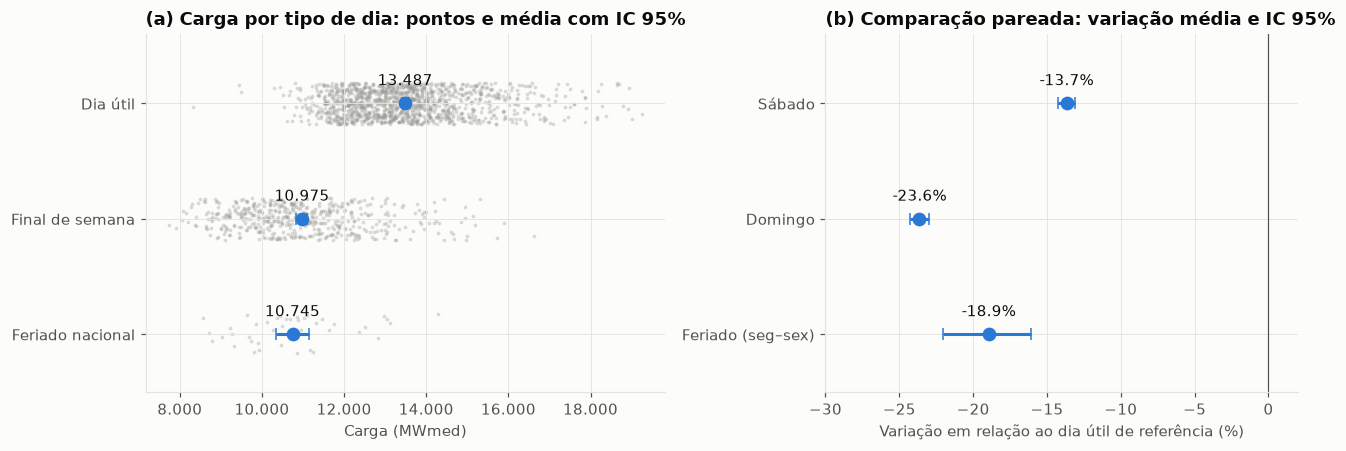

In [14]:
# --- H2: GRÁFICOS ---

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})

# (a) distribuição e média com IC 95% por tipo de dia
for i, tipo in enumerate(ordem_tipos):
    x = grupos[tipo]
    # Deslocamento vertical aleatório para espalhar os pontos
    jitter = rng.uniform(-0.18, 0.18, len(x))
    ax1.scatter(x, i + jitter, s=6, color=COR["cinza"], alpha=0.35, linewidths=0)
    # Média com barra de IC 95%
    media, inf, sup = ic_media(x)
    ax1.errorbar(media, i, xerr=[[media - inf], [sup - media]], fmt="o",
                 color=COR["azul"], markersize=8, capsize=4, elinewidth=2)
    # Valor da média acima do ponto
    ax1.annotate(f"{media:,.0f}".replace(",", "."), (media, i), xytext=(0, 12),
                 textcoords="offset points", ha="center", color=COR["texto"])
ax1.set_yticks(range(3), ordem_tipos)
ax1.set_ylim(2.5, -0.6)  # eixo invertido, com folga para os rótulos
ax1.xaxis.set_major_formatter(milhar)
ax1.set_xlabel("Carga (MWmed)")
ax1.set_title("(a) Carga por tipo de dia: pontos e média com IC 95%")

# (b) variação pareada com IC 95% (bootstrap)
rotulos = ["Sábado", "Domingo", "Feriado (seg–sex)"]
# Variação média de cada comparação com barra de IC 95%
for i, (_, linha) in enumerate(testes_pareados.iterrows()):
    ax2.errorbar(linha["variacao_media_pct"], i,
                 xerr=[[linha["variacao_media_pct"] - linha["ic95_inferior"]],
                       [linha["ic95_superior"] - linha["variacao_media_pct"]]],
                 fmt="o", color=COR["azul"], markersize=8, capsize=4, elinewidth=2)
    ax2.annotate(f"{linha['variacao_media_pct']:.1f}%", (linha["variacao_media_pct"], i),
                 xytext=(0, 12), textcoords="offset points", ha="center", color=COR["texto"])
# Linha de referência: sem variação
ax2.axvline(0, color=COR["texto2"], linewidth=0.8)
ax2.set_yticks(range(3), rotulos)
ax2.set_ylim(2.5, -0.6)  # eixo invertido, com folga para os rótulos
ax2.set_xlim(-30, 2)
ax2.set_xlabel("Variação em relação ao dia útil de referência (%)")
ax2.set_title("(b) Comparação pareada: variação média e IC 95%")

fig.tight_layout()
plt.show()

,recorte,variavel,n,rho_spearman,ic95_inferior,ic95_superior,p_valor
0,Todos os dias,temperatura,1826,0.491,0.453,0.527,2.499701e-111
1,Todos os dias,umidade,1826,-0.001,-0.047,0.045,9.634025e-01
2,Todos os dias,precipitacao,1826,0.152,0.107,0.197,6.473876e-11
3,Dias úteis,temperatura,1276,0.646,0.609,0.679,2.267874e-151
4,Dias úteis,umidade,1276,-0.028,-0.083,0.027,3.104661e-01
5,Dias úteis,precipitacao,1276,0.150,0.096,0.204,7.227035e-08


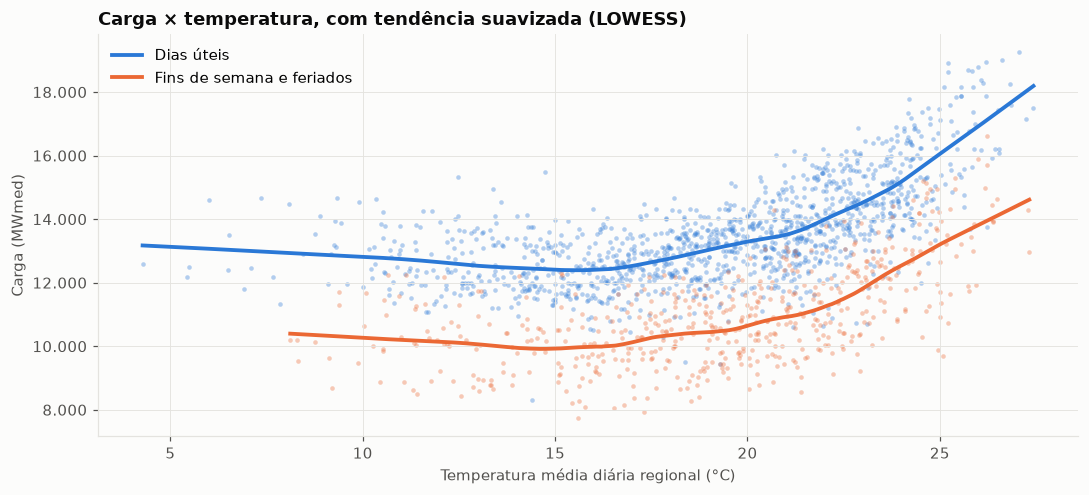

In [15]:
# --- H1: CORRELAÇÕES DE SPEARMAN ---

# Função auxiliar: IC 95% da correlação de Spearman
def ic_spearman(r, n, nivel=0.95):
    """IC para a correlação de Spearman (Fisher z com correção de Bonett e Wright)."""
    z = np.arctanh(r)
    erro = np.sqrt((1 + r**2 / 2) / (n - 3))
    zc = stats.norm.ppf((1 + nivel) / 2)
    return np.tanh(z - zc * erro), np.tanh(z + zc * erro)


# Correlação da carga com cada variável climática,
# para todos os dias e somente para dias úteis
uteis = df[df["tipo_dia"] == "Dia útil"]
linhas = []
for recorte, dados in [("Todos os dias", df), ("Dias úteis", uteis)]:
    for variavel in ["temperatura", "umidade", "precipitacao"]:
        r, p = stats.spearmanr(dados["carga"], dados[variavel])
        inf, sup = ic_spearman(r, len(dados))
        linhas.append((recorte, variavel, len(dados), r, inf, sup, p))

# Organizar e exibir as correlações
correlacoes = pd.DataFrame(linhas, columns=[
    "recorte", "variavel", "n", "rho_spearman", "ic95_inferior", "ic95_superior", "p_valor",
])
display(correlacoes.round({"rho_spearman": 3, "ic95_inferior": 3, "ic95_superior": 3}))

# Dispersão carga x temperatura com curva LOWESS
fig, ax = plt.subplots(figsize=(10, 4.6))
# Dois grupos: dias úteis e demais dias
series = [
    ("Dias úteis", df["tipo_dia"] == "Dia útil", COR["azul"]),
    ("Fins de semana e feriados", df["tipo_dia"] != "Dia útil", COR["laranja"]),
]
for rotulo, mascara, cor in series:
    sub = df[mascara]
    # Pontos de cada dia e curva suavizada do grupo
    ax.scatter(sub["temperatura"], sub["carga"], s=9, color=cor, alpha=0.35, linewidths=0)
    curva = lowess(sub["carga"], sub["temperatura"], frac=0.3)
    ax.plot(curva[:, 0], curva[:, 1], color=cor, linewidth=2.5, label=rotulo)
ax.yaxis.set_major_formatter(milhar)
ax.set_xlabel("Temperatura média diária regional (°C)")
ax.set_ylabel("Carga (MWmed)")
ax.set_title("Carga × temperatura, com tendência suavizada (LOWESS)")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

In [16]:
# --- H1: ESCOLHA DOS LIMIARES DE GRAUS-DIA ---

# Indicador de feriado que cai em dia útil (segunda a sexta)
df["feriado_semana"] = (df["is_feriado"] & (df["dia_semana"] < 5)).astype(int)

# Modelo base: tendência (ano), sazonalidade (mês) e calendário
# Modelo com clima: base + graus-dia, umidade e precipitação
FORMULA_BASE = "carga ~ C(ano) + C(mes) + C(dia_semana) + feriado_semana"
FORMULA_CLIMA = FORMULA_BASE + " + hdd + cdd + umidade + precipitacao"


# HDD = frio abaixo de base_frio; CDD = calor acima de base_calor
def graus_dia(temperatura, base_frio, base_calor):
    return np.maximum(base_frio - temperatura, 0), np.maximum(temperatura - base_calor, 0)


# Busca em grade: ajustar o modelo para cada par de limiares e guardar o AIC
grade = []
for base_frio in range(10, 21):
    for base_calor in range(base_frio, 25):
        df["hdd"], df["cdd"] = graus_dia(df["temperatura"], base_frio, base_calor)
        modelo = smf.ols(FORMULA_CLIMA, df).fit()
        grade.append((base_frio, base_calor, modelo.aic, modelo.params["hdd"], modelo.params["cdd"]))

# Escolher o par de menor AIC entre os de coeficientes não negativos
grade = pd.DataFrame(grade, columns=["base_frio", "base_calor", "aic", "coef_hdd", "coef_cdd"])
validos = grade[(grade["coef_hdd"] >= 0) & (grade["coef_cdd"] >= 0)]
escolhido = validos.loc[validos["aic"].idxmin()]

# Guardar os limiares escolhidos e exibir os 5 melhores pares
BASE_FRIO, BASE_CALOR = int(escolhido["base_frio"]), int(escolhido["base_calor"])
print(f"Limiares escolhidos: frio < {BASE_FRIO} °C | calor > {BASE_CALOR} °C")
display(validos.nsmallest(5, "aic").round(1))

Limiares escolhidos: frio < 12 °C | calor > 19 °C


,base_frio,base_calor,aic,coef_hdd,coef_cdd
36,12,19,29021.5,60.1,459.0
23,11,19,29022.1,75.2,458.7
48,13,19,29022.4,41.3,459.0
9,10,19,29022.7,95.0,458.5
59,14,19,29023.3,27.8,459.0


In [17]:
# --- H1: REGRESSÃO COM ERROS-PADRÃO HAC E TESTES DE WALD ---

# Recalcular os graus-dia com os limiares escolhidos
df["hdd"], df["cdd"] = graus_dia(df["temperatura"], BASE_FRIO, BASE_CALOR)
# Erros-padrão HAC (Newey-West), robustos à autocorrelação
HAC = {"cov_type": "HAC", "cov_kwds": {"maxlags": 7}}

# Ajustar os modelos sem e com clima
modelo_base = smf.ols(FORMULA_BASE, df).fit(**HAC)
modelo_clima = smf.ols(FORMULA_CLIMA, df).fit(**HAC)

# Coeficientes climáticos
variaveis_clima = ["hdd", "cdd", "umidade", "precipitacao"]
ic = modelo_clima.conf_int()
coeficientes = pd.DataFrame({
    "coeficiente_MWmed": modelo_clima.params[variaveis_clima],
    "ic95_inferior": ic.loc[variaveis_clima, 0],
    "ic95_superior": ic.loc[variaveis_clima, 1],
    "p_valor": modelo_clima.pvalues[variaveis_clima],
})
# Efeito de cada coeficiente em % da carga média
coeficientes["efeito_pct_da_media"] = 100 * coeficientes["coeficiente_MWmed"] / df["carga"].mean()
display(coeficientes.round({c: 3 for c in coeficientes.columns if c != "p_valor"}))

# Testes de Wald (H0: coeficientes = 0)
hipoteses = {
    "Clima completo (HDD, CDD, umidade, precipitação)": "hdd = 0, cdd = 0, umidade = 0, precipitacao = 0",
    "Temperatura (HDD e CDD)": "hdd = 0, cdd = 0",
    "Somente calor (CDD)": "cdd = 0",
    "Somente frio (HDD)": "hdd = 0",
    "Umidade e precipitação": "umidade = 0, precipitacao = 0",
}
# Executar cada teste e guardar estatística, p-valor e graus de liberdade
wald = pd.DataFrame(
    [(nome, *(lambda t: (float(np.squeeze(t.statistic)), float(t.pvalue), int(t.df_denom)))(
        modelo_clima.wald_test(h, scalar=True)))
     for nome, h in hipoteses.items()],
    columns=["hipotese_nula", "qui_quadrado", "p_valor", "graus_liberdade"],
)
display(wald)

# Ganho de ajuste ao incluir o clima (com e sem controle de mês)
# Função auxiliar: R² ajustado, RMSE e MAPE de um modelo
def ajuste(formula):
    m = smf.ols(formula, df).fit()
    return m.rsquared_adj, np.sqrt(m.mse_resid), 100 * np.mean(np.abs(m.resid / df["carga"]))

# Comparar modelos com e sem clima, com e sem controle de mês
modelos = {
    "Calendário + ano + mês": FORMULA_BASE,
    "Calendário + ano + mês + clima": FORMULA_CLIMA,
    "Calendário + ano (sem mês)": FORMULA_BASE.replace(" + C(mes)", ""),
    "Calendário + ano + clima (sem mês)": FORMULA_CLIMA.replace(" + C(mes)", ""),
}
# Exibir a comparação de ajuste
pd.DataFrame(
    [(nome, *ajuste(f)) for nome, f in modelos.items()],
    columns=["modelo", "r2_ajustado", "rmse_MWmed", "mape_pct"],
).round(3)

,coeficiente_MWmed,ic95_inferior,ic95_superior,p_valor,efeito_pct_da_media
hdd,60.135,18.561,101.709,4.582851e-03,0.473
cdd,458.974,403.319,514.628,9.127415e-59,3.607
umidade,10.705,2.074,19.336,1.505521e-02,0.084
precipitacao,10.579,5.013,16.145,1.953879e-04,0.083


,hipotese_nula,qui_quadrado,p_valor,graus_liberdade
0,"Clima completo (HDD, CDD, umidade, precipitação)",301.141252,6.146431e-64,4
1,Temperatura (HDD e CDD),264.016754,4.671866e-58,2
2,Somente calor (CDD),261.257802,9.127415e-59,1
3,Somente frio (HDD),8.037114,4.582851e-03,1
4,Umidade e precipitação,45.297279,1.458213e-10,2


,modelo,r2_ajustado,rmse_MWmed,mape_pct
0,Calendário + ano + mês,0.777,900.540,5.122
1,Calendário + ano + mês + clima,0.873,678.897,3.896
2,Calendário + ano (sem mês),0.593,1216.742,7.373
3,Calendário + ano + clima (sem mês),0.861,710.833,4.087


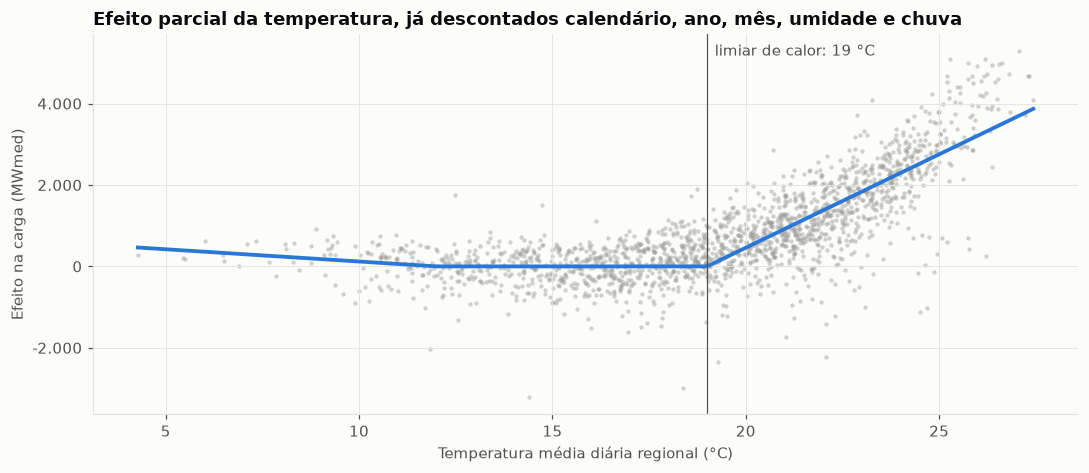

In [18]:
# --- H1: EFEITO PARCIAL DA TEMPERATURA ---

# Resíduo parcial: carga sem os efeitos de calendário, ano, mês, umidade e chuva
efeito_temp = modelo_clima.params["hdd"] * df["hdd"] + modelo_clima.params["cdd"] * df["cdd"]
# Somar o efeito da temperatura de volta ao resíduo do modelo
residuo_parcial = modelo_clima.resid + efeito_temp

# Curva do efeito estimado em uma grade de temperaturas
grade_t = np.linspace(df["temperatura"].min(), df["temperatura"].max(), 200)
hdd_g, cdd_g = graus_dia(grade_t, BASE_FRIO, BASE_CALOR)
curva = modelo_clima.params["hdd"] * hdd_g + modelo_clima.params["cdd"] * cdd_g

# Gráfico: pontos do resíduo parcial e curva estimada
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.scatter(df["temperatura"], residuo_parcial, s=8, color=COR["cinza"], alpha=0.45, linewidths=0)
ax.plot(grade_t, curva, color=COR["azul"], linewidth=2.5)
# Marcar o limiar de calor
ax.axvline(BASE_CALOR, color=COR["texto2"], linewidth=0.8)
ax.annotate(f"limiar de calor: {BASE_CALOR} °C", (BASE_CALOR, ax.get_ylim()[1]),
            xytext=(5, -14), textcoords="offset points", color=COR["texto2"])
ax.yaxis.set_major_formatter(milhar)
ax.set_xlabel("Temperatura média diária regional (°C)")
ax.set_ylabel("Efeito na carga (MWmed)")
ax.set_title("Efeito parcial da temperatura, já descontados calendário, ano, mês, umidade e chuva")
fig.tight_layout()
plt.show()

In [19]:
# --- EVENTOS: RESÍDUOS DO MODELO COM CLIMA ---

# Resíduo do modelo com clima em % do valor previsto
df["residuo_pct"] = 100 * modelo_clima.resid / modelo_clima.fittedvalues
# Desvio-padrão do resíduo, que define a faixa usual
desvio_residuo = df["residuo_pct"].std()
print(f"Desvio-padrão do resíduo: {desvio_residuo:.1f}% (faixa usual ≈ ±{2 * desvio_residuo:.1f}%)")

# Datas especiais móveis (a partir da Páscoa) e fixas
especiais = {}
for ano in range(2021, 2026):
    # Datas móveis calculadas a partir da Páscoa de cada ano
    pascoa = pd.Timestamp(easter(ano))
    especiais[pascoa - pd.Timedelta(days=48)] = "Carnaval (segunda)"
    especiais[pascoa - pd.Timedelta(days=47)] = "Carnaval (terça)"
    especiais[pascoa - pd.Timedelta(days=46)] = "Quarta-feira de Cinzas"
    especiais[pascoa - pd.Timedelta(days=2)] = "Sexta-feira Santa"
    especiais[pascoa + pd.Timedelta(days=60)] = "Corpus Christi"
    # Datas fixas
    especiais[pd.Timestamp(ano, 12, 24)] = "Véspera de Natal"
    especiais[pd.Timestamp(ano, 12, 31)] = "Véspera de Ano Novo"

# Marcar na base os dias que coincidem com essas datas
df["evento"] = df["data"].map(especiais)

# Recesso de fim de ano: dias úteis entre 26/12 e 06/01 sem outro evento
dia_mes = df["data"].dt.strftime("%m-%d")
recesso = ((dia_mes >= "12-26") | (dia_mes <= "01-06")) & (df["tipo_dia"] == "Dia útil") & df["evento"].isna()
df.loc[recesso, "evento"] = "Recesso de fim de ano (dias úteis 26/12–06/01)"

# Enchentes no RS: dias úteis de 06 a 29/05/2024
enchente = df["data"].between("2024-05-06", "2024-05-29") & (df["tipo_dia"] == "Dia útil")
df.loc[enchente, "evento"] = "Enchentes no RS (dias úteis 06–29/05/2024)"

# Ordem de exibição dos eventos
ordem_eventos = [
    "Sexta-feira Santa", "Corpus Christi", "Carnaval (segunda)", "Carnaval (terça)",
    "Quarta-feira de Cinzas", "Véspera de Natal", "Véspera de Ano Novo",
    "Recesso de fim de ano (dias úteis 26/12–06/01)", "Enchentes no RS (dias úteis 06–29/05/2024)",
]
# Resíduo médio, mínimo e máximo de cada evento
resumo_eventos = (
    df.dropna(subset=["evento"])
    .groupby("evento")["residuo_pct"]
    .agg(n_dias="count", residuo_medio_pct="mean", residuo_minimo_pct="min", residuo_maximo_pct="max")
    .reindex(ordem_eventos)
    .round(1)
)
display(resumo_eventos)

# Resíduo de cada data móvel, ano a ano
display(
    df.loc[df["evento"].isin(["Sexta-feira Santa", "Corpus Christi", "Carnaval (segunda)", "Carnaval (terça)"]),
           ["data", "evento", "carga", "residuo_pct"]]
    .assign(ano=lambda d: d["data"].dt.year)
    .pivot(index="evento", columns="ano", values="residuo_pct")
    .reindex(["Sexta-feira Santa", "Corpus Christi", "Carnaval (segunda)", "Carnaval (terça)"])
    .round(1)
)

Desvio-padrão do resíduo: 5.2% (faixa usual ≈ ±10.4%)


,n_dias,residuo_medio_pct,residuo_minimo_pct,residuo_maximo_pct
evento,,,,
Sexta-feira Santa,5,-23.2,-27.8,-18.9
Corpus Christi,5,-12.1,-15.2,-10.2
Carnaval (segunda),5,-4.4,-11.1,1.2
Carnaval (terça),5,-6.3,-19.1,1.1
Quarta-feira de Cinzas,5,-0.5,-13.4,10.0
Véspera de Natal,5,-11.3,-18.7,5.3
Véspera de Ano Novo,5,-14.6,-23.3,8.4
Recesso de fim de ano (dias úteis 26/12–06/01),38,-9.4,-17.8,1.1
Enchentes no RS (dias úteis 06–29/05/2024),18,-3.2,-10.5,1.1


ano,2021,2022,2023,2024,2025
evento,,,,,
Sexta-feira Santa,-20.8,-27.8,-23.9,-18.9,-24.5
Corpus Christi,-13.4,-10.9,-10.2,-15.2,-10.8
Carnaval (segunda),-8.2,-3.8,-11.1,-0.3,1.2
Carnaval (terça),-8.7,-4.4,-19.1,-0.2,1.1


Resíduo médio dos dias úteis de 06 a 29/05/2024: -3.2%
Janelas de 18 dias úteis com média igual ou menor: 8.3% de todas as janelas


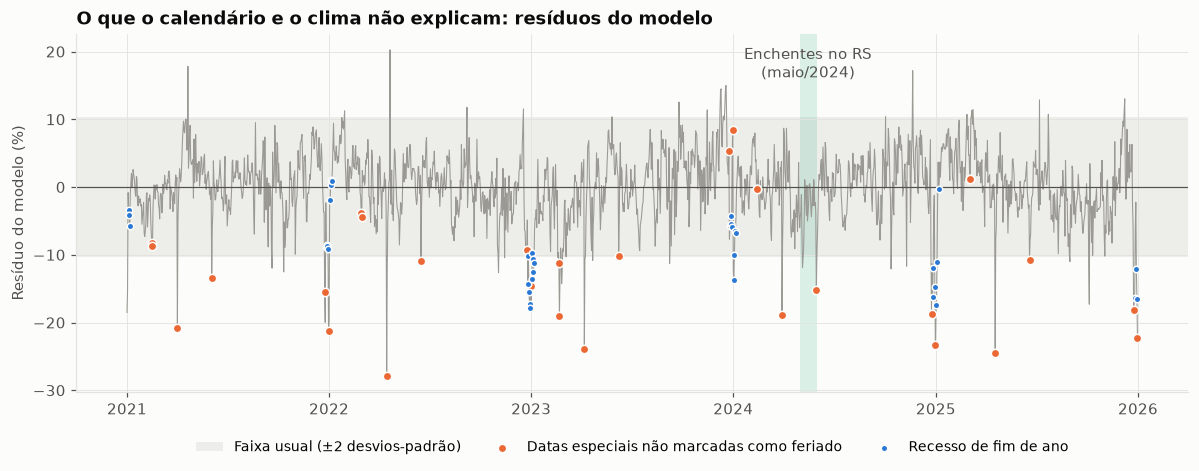

In [20]:
# --- EVENTOS: MAIO DE 2024 EM CONTEXTO ---

# Média móvel dos resíduos de 18 dias úteis (tamanho da janela de maio/2024)
residuos_uteis = df.loc[df["tipo_dia"] == "Dia útil"].set_index("data")["residuo_pct"]
janelas = residuos_uteis.rolling(enchente.sum()).mean().dropna()
# Resíduo médio do período das enchentes
valor_maio = df.loc[enchente, "residuo_pct"].mean()
# Percentual de janelas com média igual ou menor que a de maio/2024
percentil = (janelas <= valor_maio).mean() * 100
print(f"Resíduo médio dos dias úteis de 06 a 29/05/2024: {valor_maio:.1f}%")
print(f"Janelas de {enchente.sum()} dias úteis com média igual ou menor: {percentil:.1f}% de todas as janelas")

# Gráfico dos resíduos com os eventos destacados
fig, ax = plt.subplots(figsize=(11, 4.4))
# Faixa usual de ±2 desvios-padrão
ax.axhspan(-2 * desvio_residuo, 2 * desvio_residuo, color=COR["grade"], alpha=0.6, linewidth=0,
           label=f"Faixa usual (±2 desvios-padrão)")
# Série completa dos resíduos
ax.plot(df["data"], df["residuo_pct"], color=COR["cinza"], linewidth=0.7)
# Datas especiais que não estão na lista de feriados
marcados = df["evento"].isin(["Sexta-feira Santa", "Corpus Christi", "Carnaval (segunda)",
                              "Carnaval (terça)", "Véspera de Natal", "Véspera de Ano Novo"])
ax.scatter(df.loc[marcados, "data"], df.loc[marcados, "residuo_pct"], s=30, color=COR["laranja"],
           zorder=3, edgecolors=COR["fundo"], linewidths=1, label="Datas especiais não marcadas como feriado")
# Dias do recesso de fim de ano
ax.scatter(df.loc[recesso, "data"], df.loc[recesso, "residuo_pct"], s=18, color=COR["azul"],
           zorder=3, edgecolors=COR["fundo"], linewidths=1, label="Recesso de fim de ano")
# Período das enchentes no RS
ax.axvspan(pd.Timestamp("2024-05-01"), pd.Timestamp("2024-05-31"), color=COR["verde"], alpha=0.15, linewidth=0)
ax.annotate("Enchentes no RS\n(maio/2024)", (pd.Timestamp("2024-05-15"), ax.get_ylim()[1]),
            xytext=(0, -8), textcoords="offset points", ha="center", va="top", color=COR["texto2"])
ax.axhline(0, color=COR["texto2"], linewidth=0.8)
ax.set_ylabel("Resíduo do modelo (%)")
ax.set_title("O que o calendário e o clima não explicam: resíduos do modelo")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=9)
fig.tight_layout()
plt.show()

,defasagem_dias,autocorrelacao
0,1,0.692
1,2,0.388
2,7,0.820
3,14,0.761
4,21,0.758
5,28,0.709


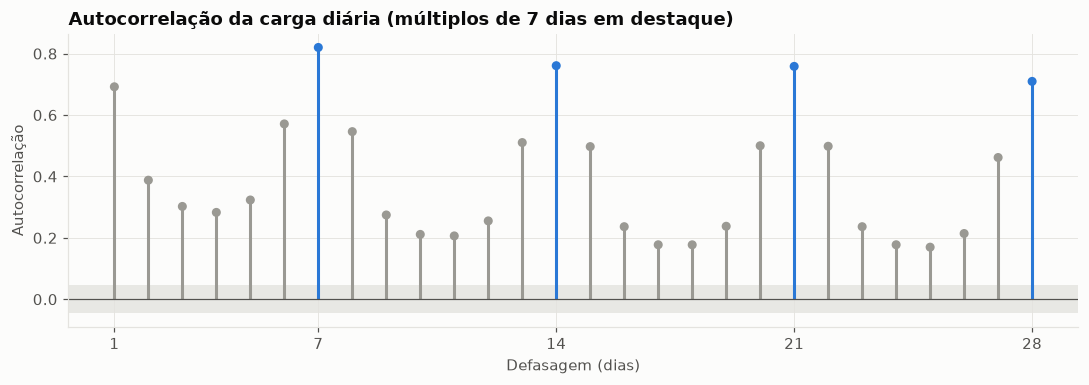

Erro percentual absoluto médio (MAPE) repetindo o dia anterior: 9.5%
Erro percentual absoluto médio (MAPE) repetindo o mesmo dia da semana anterior: 6.5%


In [21]:
# --- AUTOCORRELAÇÃO DA CARGA ---

# Autocorrelação até 28 dias (4 semanas)
n_lags = 28
valores_acf = acf(df["carga"], nlags=n_lags)
# Limite de significância de 95% para a autocorrelação
limite = 1.96 / np.sqrt(len(df))

# Exibir as defasagens mais relevantes
display(pd.DataFrame({"defasagem_dias": [1, 2, 7, 14, 21, 28],
                      "autocorrelacao": valores_acf[[1, 2, 7, 14, 21, 28]].round(3)}))

# Gráfico da ACF, com os múltiplos de 7 dias em azul
fig, ax = plt.subplots(figsize=(10, 3.6))
lags = np.arange(1, n_lags + 1)
cores = [COR["azul"] if lag % 7 == 0 else COR["cinza"] for lag in lags]
ax.vlines(lags, 0, valores_acf[1:], colors=cores, linewidth=2)
ax.scatter(lags, valores_acf[1:], color=cores, s=24, zorder=3)
ax.axhspan(-limite, limite, color=COR["grade"], alpha=0.8, linewidth=0)
ax.axhline(0, color=COR["texto2"], linewidth=0.8)
ax.set_xticks([1, 7, 14, 21, 28])
ax.set_xlabel("Defasagem (dias)")
ax.set_ylabel("Autocorrelação")
ax.set_title("Autocorrelação da carga diária (múltiplos de 7 dias em destaque)")
fig.tight_layout()
plt.show()

# Referência ingênua para a modelagem: repetir a carga de 7 dias antes
erro_ingenuo_7 = 100 * np.mean(np.abs(df["carga"] / df["carga"].shift(7) - 1))
erro_ingenuo_1 = 100 * np.mean(np.abs(df["carga"] / df["carga"].shift(1) - 1))
print(f"Erro percentual absoluto médio (MAPE) repetindo o dia anterior: {erro_ingenuo_1:.1f}%")
print(f"Erro percentual absoluto médio (MAPE) repetindo o mesmo dia da semana anterior: {erro_ingenuo_7:.1f}%")